# Benchmark edge service placement

Turn a network scenario into a measured comparison of placement strategies.
This walkthrough runs **two heuristics on the same instances**, checks their
solutions through the shared validator, and plots **served flow and elapsed
time**. It also plots actual service placements and directed routes, and
runs a separate scaling campaign up to **400 users**.

**Setup:** from the repository root, install
`python -m pip install -e ".[benchmarks]" jupyterlab`, then open this notebook
with `jupyter lab examples/benchmark_walkthrough.ipynb`. Select the Python
environment where you installed the package and use **Run All**.

The default campaign needs no GPU or Gurobi license. Outputs are replaced in
`artifacts/readme/` on each run. The README uses a reviewed snapshot of these
outputs in `docs/assets/`.

In [1]:
import importlib.metadata
import json
import platform
import subprocess
import time
from datetime import datetime, timezone
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

from service_placement import list_solvers, make_star_instance, make_tree_instance, solve
from service_placement.benchmarks.metrics import RESULT_COLUMNS, failed_row, result_row
from service_placement.domain.loads import residual_arrays
from service_placement.utils.solver_registry import REGISTRY

cwd = Path.cwd().resolve()
ROOT = next(
    (
        p
        for p in [cwd, *cwd.parents]
        if (p / "pyproject.toml").is_file() and (p / "src/service_placement").is_dir()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError("Open the notebook from this repository or its examples directory.")

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelcolor": "#334155",
        "text.color": "#0f172a",
        "svg.fonttype": "none",
        "svg.hashsalt": "service_placement-readme",
    }
)

## 1. Define a small campaign

Tree/star generators are deterministic: search seeds change solver behavior,
**not the network or demands**. Compare all methods on the same scenario and
retain failures alongside successes.

For `star`, `SIZES` means users per group; the x-axis will show total users.
Add registered solver names from `list_solvers()` only after installing their
extras. `SOLVER_OPTIONS` lets you set training budgets or search parameters.
Mathematical backends receive an explicit time limit. The default uses each
heuristic's defaults, so its search budgets can differ.

In [2]:
INSTANCE = "tree"  # "tree" or "star"
SIZES = [10, 20, 40]
SEEDS = [7, 21, 42]
NEIGHBORS = 1
GROUPS = 4  # Used only for star instances.
SOLVERS = ["fast_heuristic", "heuristic"]
SOLVER_OPTIONS = {}  # e.g. {"ppo": {"train_step": 10000, "evaluation_step": 100}}
EXACT_TIME_LIMIT = 30.0
OUTPUT_DIR = ROOT / "artifacts" / "readme"

if INSTANCE not in {"tree", "star"}:
    raise ValueError("INSTANCE must be tree or star.")
if not SIZES or not SEEDS or not SOLVERS:
    raise ValueError("Choose at least one size, seed, and solver.")
if len(SIZES) != len(set(SIZES)) or len(SEEDS) != len(set(SEEDS)):
    raise ValueError("Use distinct sizes and seeds to avoid duplicate measurements.")
if len(SOLVERS) != len(set(SOLVERS)):
    raise ValueError("Use distinct solver names.")
unknown = set(SOLVERS) - set(list_solvers())
if unknown:
    raise ValueError(f"Unknown solver names: {sorted(unknown)}")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(
    f"{len(SIZES) * len(SEEDS) * len(SOLVERS)} runs; output directory: {OUTPUT_DIR.relative_to(ROOT)}"
)

18 runs; output directory: artifacts\readme


## 2. Understand the decision

This conceptual diagram shows the placement problem and evaluation workflow.
It is not a rendering of a particular benchmark topology. Solvers choose service
hosts, routes, and served flow while respecting the modeled network constraints.

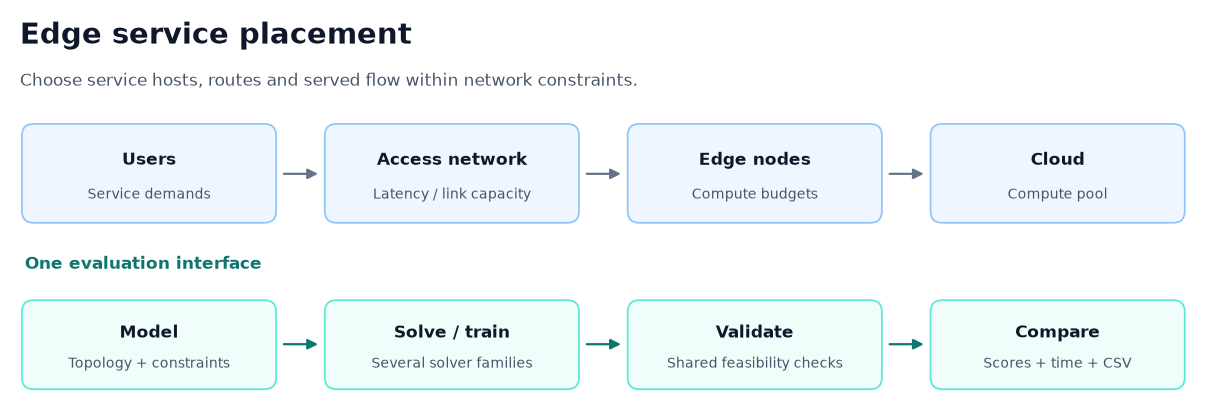

In [3]:
fig, ax = plt.subplots(figsize=(12, 4.0), layout="constrained")
ax.set_xlim(0, 12)
ax.set_ylim(0, 4)
ax.axis("off")
ax.text(0.1, 3.65, "Edge service placement", fontsize=21, weight="bold")
ax.text(
    0.1,
    3.22,
    "Choose service hosts, routes and served flow within network constraints.",
    fontsize=12,
    color="#475569",
)


def box(x, y, width, height, title, detail, facecolor, edgecolor):
    ax.add_patch(
        FancyBboxPatch(
            (x, y),
            width,
            height,
            boxstyle="round,pad=0.03,rounding_size=0.12",
            facecolor=facecolor,
            edgecolor=edgecolor,
            linewidth=1.3,
        )
    )
    ax.text(
        x + width / 2,
        y + height * 0.64,
        title,
        ha="center",
        va="center",
        weight="bold",
        fontsize=12,
    )
    ax.text(
        x + width / 2,
        y + height * 0.27,
        detail,
        ha="center",
        va="center",
        fontsize=10,
        color="#475569",
    )


def arrow(start, end, color="#64748b"):
    ax.add_patch(
        FancyArrowPatch(
            start,
            end,
            arrowstyle="-|>",
            mutation_scale=15,
            linewidth=1.6,
            color=color,
        )
    )


xs = [0.15, 3.2, 6.25, 9.3]
for x, title, detail in zip(
    xs,
    ["Users", "Access network", "Edge nodes", "Cloud"],
    ["Service demands", "Latency / link capacity", "Compute budgets", "Compute pool"],
    strict=False,
):
    box(x, 1.85, 2.5, 0.95, title, detail, "#eff6ff", "#93c5fd")
for left, right in zip(xs, xs[1:], strict=False):
    arrow((left + 2.58, 2.32), (right - 0.07, 2.32))

ax.text(0.15, 1.35, "One evaluation interface", fontsize=12, weight="bold", color="#0f766e")
for x, title, detail in zip(
    xs,
    ["Model", "Solve / train", "Validate", "Compare"],
    [
        "Topology + constraints",
        "Several solver families",
        "Shared feasibility checks",
        "Scores + time + CSV",
    ],
    strict=False,
):
    box(x, 0.15, 2.5, 0.85, title, detail, "#f0fdfa", "#5eead4")
for left, right in zip(xs, xs[1:], strict=False):
    arrow((left + 2.58, 0.58), (right - 0.07, 0.58), color="#0f766e")

fig.savefig(OUTPUT_DIR / "network-overview.svg", metadata={"Date": None})
plt.show()
plt.close(fig)

## 3. Execute and keep all outcomes

Each size creates one shared problem. Every solver runs with every search seed;
`solve()` validates each returned candidate and recomputes its score only when
feasible. Errors and invalid candidates are retained in the CSV. The score is
**sum of served demand flows in the model's units**, not a measured production
throughput or a latency reduction.

In [4]:
def git_output(*args):
    try:
        return subprocess.check_output(
            ["git", "-C", str(ROOT), *args],
            text=True,
            stderr=subprocess.DEVNULL,
            timeout=10,
        ).strip()
    except (OSError, subprocess.SubprocessError):
        return None


def package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


protocol = {
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
    "instance": INSTANCE,
    "sizes": SIZES,
    "search_seeds": SEEDS,
    "neighbors": NEIGHBORS,
    "groups": GROUPS if INSTANCE == "star" else 1,
    "solvers": SOLVERS,
    "solver_options": SOLVER_OPTIONS,
    "solver_defaults": "Defaults of the recorded source revision unless explicitly overridden.",
    "mathematical_time_limit_seconds": EXACT_TIME_LIMIT,
    "instance_generation": "Deterministic; search seeds do not randomize instances.",
    "runtime": "Wall seconds for solver construction, execution and validation; includes RL training and evaluation.",
    "aggregation": "Mean and observed min/max across feasible runs; no confidence intervals.",
    "git_revision": git_output("rev-parse", "HEAD"),
    "git_working_tree": git_output("status", "--porcelain"),
    "python": platform.python_version(),
    "platform": platform.platform(),
    "processor": platform.processor(),
    "packages": {
        name: package_version(name)
        for name in [
            "service-placement-benchmarks",
            "numpy",
            "networkx",
            "pandas",
            "matplotlib",
            "pyomo",
            "gurobipy",
            "cma",
            "torch",
            "stable-baselines3",
        ]
    },
}

rows = []
for size in SIZES:
    if INSTANCE == "tree":
        problem = make_tree_instance(n_users=size, neighbors=NEIGHBORS)
        users, groups = size, 1
    else:
        problem = make_star_instance(n_groups=GROUPS, users_per_group=size, neighbors=NEIGHBORS)
        users, groups = GROUPS * size, GROUPS
    for seed in SEEDS:
        args = SimpleNamespace(instance=INSTANCE, neighbors=NEIGHBORS, seed=seed)
        for name in SOLVERS:
            started = time.perf_counter()
            try:
                result = solve(
                    problem,
                    solver=name,
                    seed=seed,
                    solver_options=SOLVER_OPTIONS.get(name, {}),
                    time_limit=EXACT_TIME_LIMIT if REGISTRY[name].mathematical else None,
                )
                row = result_row(args, name, users, groups, result)
            except Exception as error:
                row = failed_row(
                    args,
                    name,
                    users,
                    groups,
                    time.perf_counter() - started,
                    f"{type(error).__name__}: {error}",
                )
            rows.append(row)
            print(
                f"users={users:3d} seed={seed:2d} {name:16s} "
                f"status={row['status']} score={row['score']}"
            )

results = pd.DataFrame(rows, columns=RESULT_COLUMNS)
results["score"] = pd.to_numeric(results["score"], errors="coerce")
results["runtime"] = pd.to_numeric(results["runtime"], errors="coerce")
results.to_csv(OUTPUT_DIR / "benchmark-results.csv", index=False)
protocol["completed_at_utc"] = datetime.now(timezone.utc).isoformat()
protocol["runs"] = len(results)
protocol["feasible_runs"] = int(results["feasible"].sum())
(OUTPUT_DIR / "benchmark-protocol.json").write_text(
    json.dumps(protocol, indent=2) + "\n",
    encoding="utf-8",
)
display(results[["solver", "users", "seed", "score", "runtime", "status", "feasible"]])

users= 10 seed= 7 fast_heuristic   status=feasible score=70.0


users= 10 seed= 7 heuristic        status=feasible score=70.0
users= 10 seed=21 fast_heuristic   status=feasible score=70.0


users= 10 seed=21 heuristic        status=feasible score=69.0
users= 10 seed=42 fast_heuristic   status=feasible score=70.0


users= 10 seed=42 heuristic        status=feasible score=58.0
users= 20 seed= 7 fast_heuristic   status=feasible score=140.0


users= 20 seed= 7 heuristic        status=feasible score=136.0
users= 20 seed=21 fast_heuristic   status=feasible score=140.0


...

users= 40 seed=21 fast_heuristic   status=feasible score=270.0


users= 40 seed=21 heuristic        status=feasible score=254.0


users= 40 seed=42 fast_heuristic   status=feasible score=270.0


users= 40 seed=42 heuristic        status=feasible score=270.0


,solver,users,seed,score,runtime,status,feasible
0,fast_heuristic,10,7,70.0,0.006369,feasible,True
1,heuristic,10,7,70.0,0.476104,feasible,True
2,fast_heuristic,10,21,70.0,0.003780,feasible,True
3,heuristic,10,21,69.0,0.490967,feasible,True
4,fast_heuristic,10,42,70.0,0.003109,feasible,True
5,heuristic,10,42,58.0,0.339600,feasible,True
6,fast_heuristic,20,7,140.0,0.009056,feasible,True
7,heuristic,20,7,136.0,2.204056,feasible,True
8,fast_heuristic,20,21,140.0,0.011809,feasible,True
9,heuristic,20,21,129.0,2.676411,feasible,True


## 4. Inspect feasibility before performance

Failures remain visible here, even when curves show only feasible results.
Do not rank methods using scores alone when they succeed on different subsets.
Three search seeds on deterministic instances are a small demonstration, not
evidence of generalization across networks or a statistically robust ranking.

In [5]:
summary = results.groupby(["solver", "users"], as_index=False).agg(
    runs=("feasible", "size"),
    feasible_runs=("feasible", "sum"),
)
summary["feasibility_rate"] = summary["feasible_runs"] / summary["runs"]
display(summary)
failures = results.loc[~results["feasible"], ["solver", "users", "seed", "status", "error"]]
if not failures.empty:
    display(failures)
else:
    print("All candidates in this campaign passed the shared feasibility validator.")

,solver,users,runs,feasible_runs,feasibility_rate
0,fast_heuristic,10,3,3,1.0
1,fast_heuristic,20,3,3,1.0
2,fast_heuristic,40,3,3,1.0
3,heuristic,10,3,3,1.0
4,heuristic,20,3,3,1.0
5,heuristic,40,3,3,1.0


All candidates in this campaign passed the shared feasibility validator.


## 5. Compare served flow and elapsed time

Higher served flow is better on the same instance. Lower runtime is better for
a comparable solution quality. Lines show means and bands show the observed
minimum/maximum over feasible runs. These are **not confidence intervals**.
Timings depend on the host, runtime environment, and solver budgets; RL solver
time includes training, so it must not be presented as inference latency.

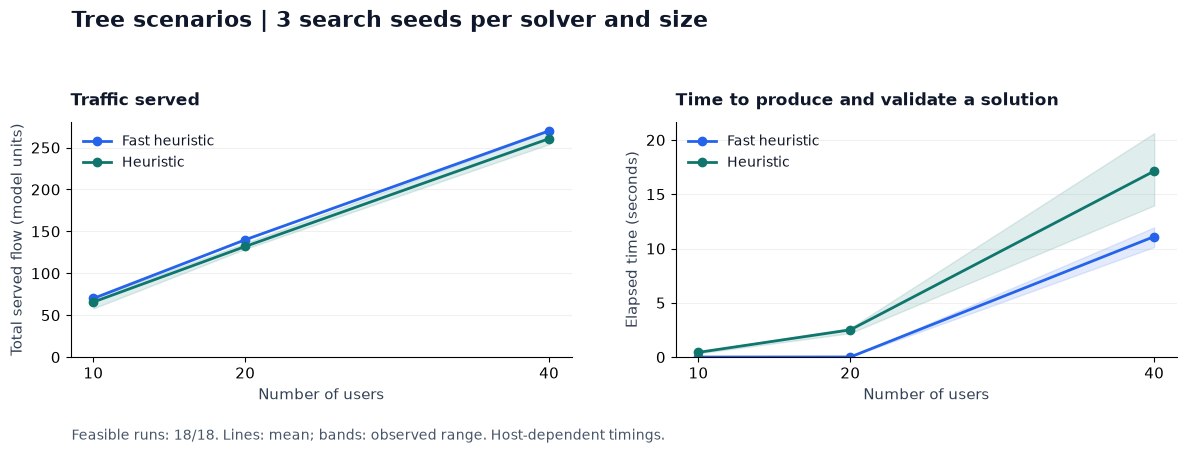

In [6]:
valid = results.loc[results["feasible"]].copy()
if valid.empty:
    raise RuntimeError("No feasible runs to plot; inspect the saved CSV errors and dependencies.")

colors = ["#2563eb", "#0f766e", "#d97706", "#9333ea", "#db2777"]
labels = {"fast_heuristic": "Fast heuristic", "heuristic": "Heuristic"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for index, name in enumerate(SOLVERS):
    group = valid.loc[valid["solver"] == name]
    if group.empty:
        continue
    color = colors[index % len(colors)]
    for ax, metric in zip(axes, ["score", "runtime"], strict=False):
        stats = group.groupby("users")[metric].agg(["mean", "min", "max"]).sort_index()
        x = stats.index.to_numpy()
        ax.plot(
            x,
            stats["mean"].to_numpy(),
            marker="o",
            linewidth=2,
            label=labels.get(name, name),
            color=color,
        )
        ax.fill_between(
            x, stats["min"].to_numpy(), stats["max"].to_numpy(), alpha=0.13, color=color
        )

for ax, title, ylabel in zip(
    axes,
    ["Traffic served", "Time to produce and validate a solution"],
    ["Total served flow (model units)", "Elapsed time (seconds)"],
    strict=False,
):
    ax.set_title(title, loc="left", fontsize=12, weight="bold", pad=12)
    ax.set_xlabel("Number of users")
    ax.set_ylabel(ylabel)
    ax.set_xticks(sorted(results["users"].unique()))
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.18)
    ax.legend(frameon=False, fontsize=10)

fig.suptitle(
    f"{INSTANCE.title()} scenarios | {len(SEEDS)} search seeds per solver and size",
    fontsize=16,
    weight="bold",
    x=0.065,
    ha="left",
)
note = (
    f"Feasible runs: {int(results['feasible'].sum())}/{len(results)}. "
    "Lines: mean; bands: observed range. Host-dependent timings."
)
fig.text(0.065, 0.025, note, fontsize=10, color="#475569")
fig.tight_layout(rect=(0, 0.07, 1, 0.92), w_pad=2.5)
fig.savefig(OUTPUT_DIR / "benchmark-overview.png", dpi=160, facecolor="white")
plt.show()
plt.close(fig)

## 6. See placements and directed routing on a solved network

The following figures read **`Solution.y`, `Solution.x`, and `Solution.q`** from
validated solver results. Orange outlines mark nodes hosting services; detailed
node labels list the service IDs. Gray lines are available physical links.
In the aggregate view, colored arrows follow directed arcs carrying traffic,
their width reflects traffic, and their color shows directional capacity usage.

The second panel isolates one service. Each demand has its own route color,
including a local demand whose origin is already the service host (zero hops).
All flow and latency metrics are calculated from the **full solution**, including
other services sharing the same arcs. Infrastructure labels follow the synthetic
builders: `U` = user, `AP` = access point, `C` = cloud.

In [3]:
def star_positions(groups, users_per_group):
    """Keep access groups distinct instead of overlaying all users in the center."""
    n_users = groups * users_per_group
    radius = max(3.0, groups * 0.42)
    positions = {n_users + groups: np.array([0.0, 0.0])}
    for group in range(groups):
        angle = np.pi / 2 + 2 * np.pi * group / groups
        direction = np.array([np.cos(angle), np.sin(angle)])
        positions[n_users + group] = direction * (radius - 1.65)
        center = direction * radius
        for user in range(users_per_group):
            offset_angle = 2 * np.pi * user / users_per_group
            positions[group * users_per_group + user] = center + 0.65 * np.array(
                [np.cos(offset_angle), np.sin(offset_angle)]
            )
    return positions


def node_name(node, users, groups):
    if node < users:
        return f"U{node}"
    return "C" if node == users + groups else f"AP{node - users}"


def service_routes(problem, result, service):
    """Return actual used-arc graphs, including local demands with zero arcs."""
    data, solution = problem.data, result.solution
    host = int(np.flatnonzero(solution.y[service] > 0.5)[0])
    routes = []
    for demand in np.flatnonzero(data.demand_to_service == service):
        indices = np.flatnonzero(solution.x[demand] > 0.5)
        graph = nx.DiGraph()
        graph.add_nodes_from([int(data.origins[demand]), host])
        graph.add_edges_from(data.arcs[int(a)] for a in indices)
        path = nx.shortest_path(graph, int(data.origins[demand]), host)
        routes.append((int(demand), path, indices))
    return host, routes


def draw_solution(
    ax, problem, result, positions, users, groups, service=None, detailed=False, focus_only=False
):
    """Draw validated placement and actual directed traffic, with canonical arc ordering."""
    result.validation.raise_if_infeasible()
    solution, data = result.solution, problem.data
    loads = residual_arrays(data, solution.x, solution.y, solution.q)
    host_count = (solution.y > 0.5).sum(axis=0)
    all_nodes = list(range(data.n_nodes))
    routes = []
    if service is not None:
        host, routes = service_routes(problem, result, service)
        if focus_only:
            all_nodes = sorted({node for _, route, _ in routes for node in route} | {host})
            graph = nx.Graph()
            graph.add_nodes_from(all_nodes)
            graph.add_edges_from(
                (u, v) for _, route, _ in routes for u, v in zip(route, route[1:], strict=False)
            )
            positions = nx.spring_layout(graph, seed=42)

    background = nx.Graph(problem.network_graph.nx_graph).subgraph(all_nodes)
    nx.draw_networkx_edges(
        background, positions, ax=ax, edge_color="#cbd5e1", width=0.65, alpha=0.45
    )
    graph = problem.network_graph.nx_graph.subgraph(all_nodes)
    dense = len(all_nodes) > 80
    node_sizes = [12 if dense else 540 for _ in all_nodes]
    for index, node in enumerate(all_nodes):
        if node >= users:
            node_sizes[index] = 180 if dense else 780
    nx.draw_networkx_nodes(
        graph,
        positions,
        nodelist=all_nodes,
        node_size=node_sizes,
        ax=ax,
        node_color=[
            "#dbeafe" if n < users else "#99f6e4" if n < users + groups else "#c4b5fd"
            for n in all_nodes
        ],
        edgecolors=["#f97316" if host_count[n] else "#94a3b8" for n in all_nodes],
        linewidths=[(0.9 if dense else 2.0) if host_count[n] else 0.6 for n in all_nodes],
    )

    labels = {}
    for node in all_nodes:
        if not dense or node >= users:
            label = node_name(node, users, groups)
            services = np.flatnonzero(solution.y[:, node] > 0.5)
            if detailed and len(services):
                label += "\n" + ",".join(f"S{s}" for s in services)
            elif dense and len(services):
                label += f"\n{len(services)} svc"
            labels[node] = label
    nx.draw_networkx_labels(
        graph, positions, labels=labels, ax=ax, font_size=7 if dense else 9, font_weight="bold"
    )

    if service is None:
        active = np.flatnonzero(loads["edge_load"] > 1e-9)
        utilization = loads["edge_load"][active] / data.arc_capacities[active]
        max_traffic = max(float(loads["edge_load"].max()), 1e-9)
        nx.draw_networkx_edges(
            graph,
            positions,
            ax=ax,
            edgelist=[data.arcs[int(a)] for a in active],
            edge_color=utilization,
            edge_cmap=plt.get_cmap("YlOrRd"),
            edge_vmin=0,
            edge_vmax=1,
            width=0.7 + 3.0 * np.sqrt(loads["edge_load"][active] / max_traffic),
            arrows=True,
            arrowsize=8 if dense else 15,
            node_size=12 if dense else 600,
            connectionstyle="arc3,rad=0.09",
            alpha=0.9,
        )
        ax.set_title("All services: placement + aggregate routing", fontsize=12, pad=12)
    else:
        route_colors = ["#2563eb", "#0f766e", "#9333ea", "#db2777"]
        route_lines = []
        for index, (demand, path, indices) in enumerate(routes):
            color = route_colors[index % len(route_colors)]
            edges = [data.arcs[int(a)] for a in indices]
            if edges:
                nx.draw_networkx_edges(
                    graph,
                    positions,
                    ax=ax,
                    edgelist=edges,
                    edge_color=color,
                    width=2.8,
                    arrows=True,
                    arrowsize=19,
                    node_size=600,
                    connectionstyle=f"arc3,rad={0.12 + 0.05 * index}",
                )
            origin = int(data.origins[demand])
            nx.draw_networkx_nodes(
                graph,
                positions,
                nodelist=[origin],
                node_color="none",
                node_size=900,
                edgecolors=color,
                linewidths=2,
                ax=ax,
            )
            route_text = " -> ".join(node_name(n, users, groups) for n in path)
            if len(path) == 1:
                route_text += " (local, zero hops)"
            route_lines.append(f"d{demand}: {route_text}; flow={solution.q[demand]:g}")
        nx.draw_networkx_nodes(
            graph,
            positions,
            nodelist=[host],
            node_shape="s",
            node_size=1000,
            node_color="none",
            edgecolors="#f97316",
            linewidths=2.3,
            ax=ax,
        )
        ax.text(
            0.0,
            -0.06,
            "\n".join(route_lines),
            transform=ax.transAxes,
            fontsize=9,
            va="top",
            color="#334155",
        )
        ax.set_title(
            f"Service S{service} hosted at {node_name(host, users, groups)}", fontsize=12, pad=12
        )
    ax.axis("off")
    ax.margins(0.18)
    return loads


def solution_figure(
    problem,
    result,
    positions,
    users,
    groups,
    filename,
    title,
    service=0,
    detailed=True,
    focus_only=False,
):
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.6))
    loads = draw_solution(axes[0], problem, result, positions, users, groups, detailed=detailed)
    draw_solution(
        axes[1],
        problem,
        result,
        positions,
        users,
        groups,
        service=service,
        detailed=detailed,
        focus_only=focus_only,
    )
    fig.suptitle(title, fontsize=17, weight="bold", y=0.99)
    fig.text(
        0.04,
        0.925,
        f"{result.solver} | seed {result.seed} | {problem.data.n_nodes} nodes | "
        f"{problem.data.n_arcs} directed arcs | {problem.data.n_services} services | "
        f"served flow {result.objective:g} | feasible",
        fontsize=10,
        color="#475569",
    )
    fig.legend(
        handles=[
            Line2D(
                [],
                [],
                marker="o",
                linestyle="none",
                markerfacecolor="#dbeafe",
                markeredgecolor="#94a3b8",
                label="User",
            ),
            Line2D(
                [],
                [],
                marker="o",
                linestyle="none",
                markerfacecolor="#99f6e4",
                markeredgecolor="#94a3b8",
                label="Access point",
            ),
            Line2D(
                [],
                [],
                marker="o",
                linestyle="none",
                markerfacecolor="#c4b5fd",
                markeredgecolor="#94a3b8",
                label="Cloud",
            ),
            Line2D(
                [],
                [],
                marker="o",
                linestyle="none",
                markerfacecolor="white",
                markeredgecolor="#f97316",
                markeredgewidth=2,
                label="Hosts service(s)",
            ),
            Line2D([], [], color="#cbd5e1", label="Available link"),
        ],
        loc="lower center",
        ncol=5,
        frameon=False,
        fontsize=9,
        bbox_to_anchor=(0.5, 0.0),
    )
    fig.subplots_adjust(top=0.84, bottom=0.2, left=0.025, right=0.94, wspace=0.12)
    color_ax = fig.add_axes([0.955, 0.26, 0.012, 0.5])
    fig.colorbar(
        ScalarMappable(norm=Normalize(0, 1), cmap="YlOrRd"),
        cax=color_ax,
        label="Directed arc capacity used (all services)",
    )
    fig.savefig(OUTPUT_DIR / filename, dpi=160, facecolor="white", bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return loads

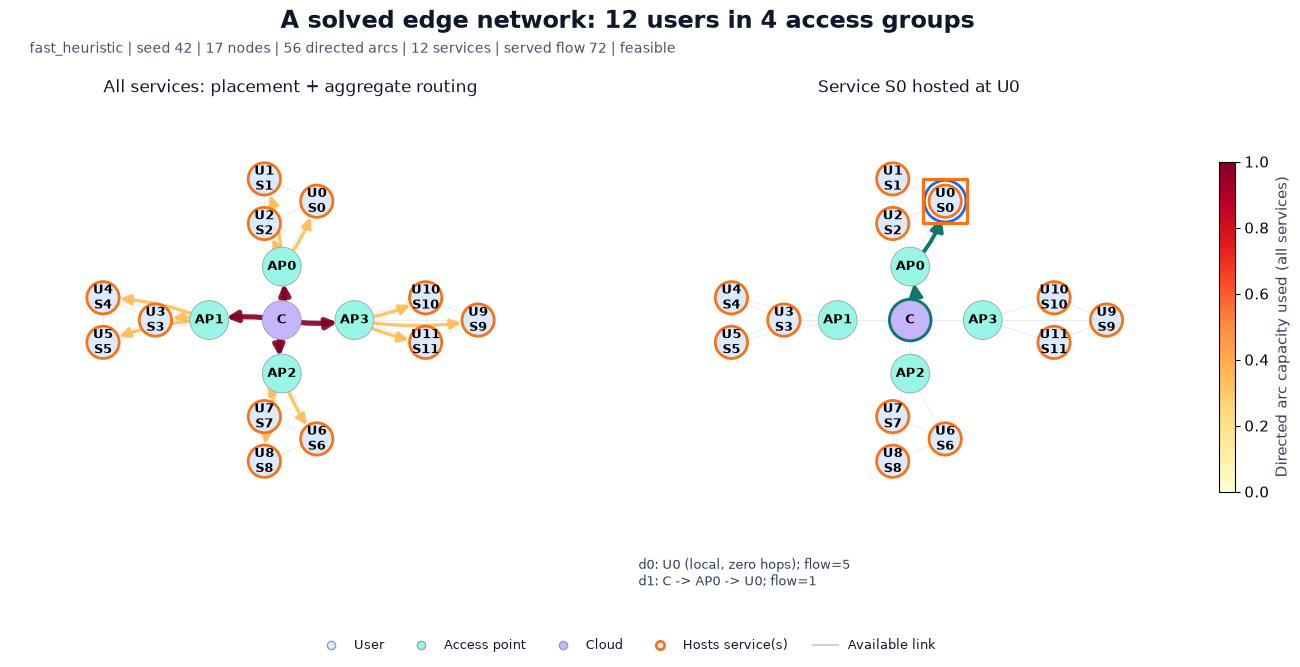

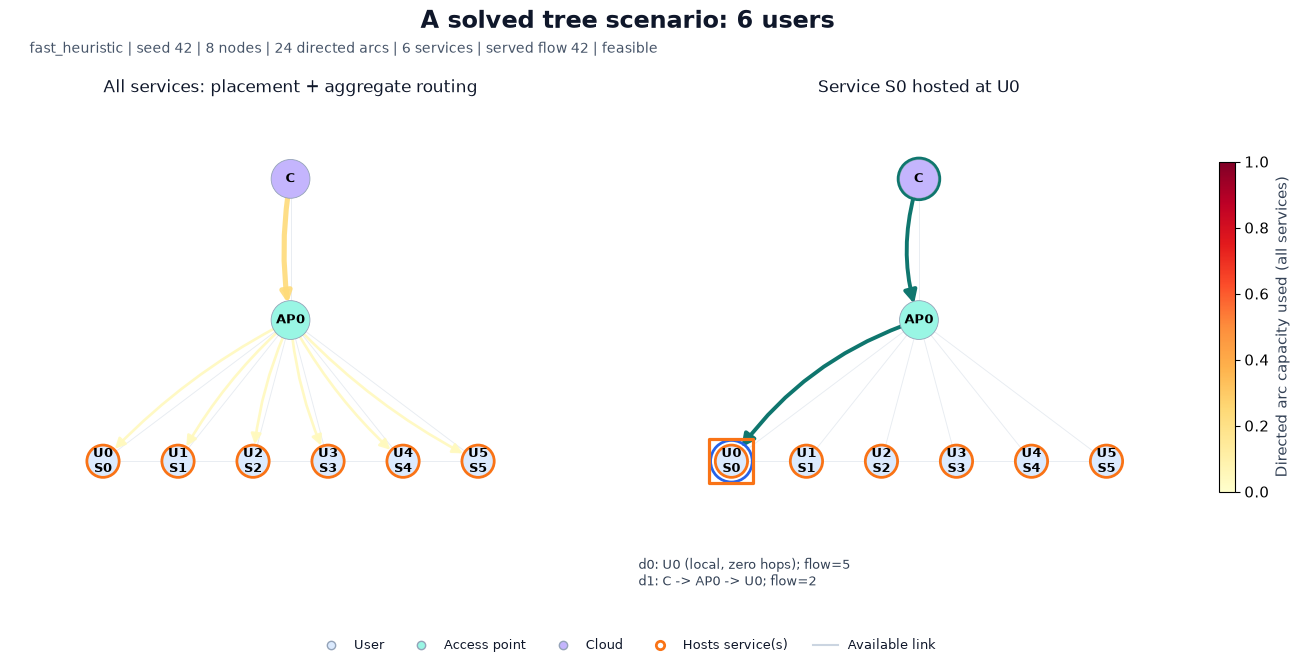

In [4]:
network_cases = []
small_star = make_star_instance(n_groups=4, users_per_group=3, neighbors=1)
small_star_result = solve(small_star, solver="fast_heuristic", seed=42)
small_star_result.validation.raise_if_infeasible()
solution_figure(
    small_star,
    small_star_result,
    star_positions(4, 3),
    12,
    4,
    "service-placement-routing.png",
    "A solved edge network: 12 users in 4 access groups",
)
network_cases.append(("small_star", small_star, small_star_result, 12, 4))

small_tree = make_tree_instance(n_users=6, neighbors=1)
small_tree_result = solve(small_tree, solver="fast_heuristic", seed=42)
tree_positions = {n: np.array([n - 2.5, 0.0]) for n in range(6)}
tree_positions.update({6: np.array([0.0, 1.5]), 7: np.array([0.0, 3.0])})
solution_figure(
    small_tree,
    small_tree_result,
    tree_positions,
    6,
    1,
    "tree-placement-routing.png",
    "A solved tree scenario: 6 users",
)
network_cases.append(("small_tree", small_tree, small_tree_result, 6, 1))

## 7. Scale to 400 users

This **separate campaign** scales a grouped star network from 40 to 400 users
by adding access groups of 20 users each. It runs `fast_heuristic` with an
explicitly bounded search (8 iterations, patience 3, 4 candidate nodes, 2 path
candidates) and three seeds. The same settings apply at every size. These
measurements illustrate scaling for this configuration; they are not a solver
ranking or a comparison to the default-budget tree campaign above.

The CSV retains failures, node/arc/service/demand counts, and served-flow
fractions. Runtime includes solver construction and validation. Larger runs can
take several minutes together on a CPU. Adjust the parameter cell below to
choose a different scale or search budget.

In [9]:
LARGE_GROUP_COUNTS = [2, 5, 10, 20]
LARGE_USERS_PER_GROUP = 20
LARGE_SEEDS = [7, 21, 42]
LARGE_SOLVER = "fast_heuristic"
LARGE_OPTIONS = {"max_iter": 8, "patience": 3, "candidate_nodes": 4, "limit_shortest_path": 2}
LARGE_NEIGHBORS = 1

large_protocol = {
    key: protocol[key]
    for key in ["git_revision", "git_working_tree", "python", "platform", "processor", "packages"]
}
large_protocol.update(
    {
        "started_at_utc": datetime.now(timezone.utc).isoformat(),
        "instance": "star",
        "group_counts": LARGE_GROUP_COUNTS,
        "users_per_group": LARGE_USERS_PER_GROUP,
        "neighbors": LARGE_NEIGHBORS,
        "search_seeds": LARGE_SEEDS,
        "solver": LARGE_SOLVER,
        "solver_options": LARGE_OPTIONS,
        "scaling": "Access groups grow; each group contains 20 users in this run.",
        "runtime": protocol["runtime"],
        "aggregation": protocol["aggregation"],
    }
)
large_rows = []
large_example = None
for groups in LARGE_GROUP_COUNTS:
    problem = make_star_instance(
        n_groups=groups, users_per_group=LARGE_USERS_PER_GROUP, neighbors=LARGE_NEIGHBORS
    )
    users = groups * LARGE_USERS_PER_GROUP
    for seed in LARGE_SEEDS:
        print(
            f"Solving {users} users ({problem.data.n_nodes} nodes, "
            f"{problem.data.n_arcs} arcs), seed {seed}...",
            flush=True,
        )
        args = SimpleNamespace(instance="star", neighbors=LARGE_NEIGHBORS, seed=seed)
        started = time.perf_counter()
        try:
            result = solve(problem, solver=LARGE_SOLVER, seed=seed, solver_options=LARGE_OPTIONS)
            row = result_row(args, LARGE_SOLVER, users, groups, result)
            if groups == max(LARGE_GROUP_COUNTS) and result.validation.feasible:
                large_example = (problem, result, users, groups)
        except Exception as error:
            row = failed_row(
                args,
                LARGE_SOLVER,
                users,
                groups,
                time.perf_counter() - started,
                f"{type(error).__name__}: {error}",
            )
        row.update(
            nodes=problem.data.n_nodes,
            arcs=problem.data.n_arcs,
            services=problem.data.n_services,
            demands=problem.data.n_demands,
            requested_flow=float(problem.data.max_flows.sum()),
        )
        large_rows.append(row)
        print(f"  {row['status']}: score={row['score']}, runtime={row['runtime']:.3f}s", flush=True)

large_results = pd.DataFrame(large_rows)
large_results["score"] = pd.to_numeric(large_results["score"], errors="coerce")
large_results["served_fraction"] = large_results["score"] / large_results["requested_flow"]
large_results.to_csv(OUTPUT_DIR / "large-benchmark-results.csv", index=False)
large_protocol.update(
    completed_at_utc=datetime.now(timezone.utc).isoformat(),
    runs=len(large_results),
    feasible_runs=int(large_results["feasible"].sum()),
)
(OUTPUT_DIR / "large-benchmark-protocol.json").write_text(
    json.dumps(large_protocol, indent=2) + "\n", encoding="utf-8"
)
display(
    large_results[
        [
            "users",
            "nodes",
            "arcs",
            "services",
            "demands",
            "seed",
            "score",
            "served_fraction",
            "runtime",
            "feasible",
            "status",
        ]
    ]
)
if not large_results["feasible"].all():
    display(large_results.loc[~large_results["feasible"], ["users", "seed", "status", "error"]])

Solving 40 users (43 nodes, 164 arcs), seed 7...


  feasible: score=256.0, runtime=0.508s


Solving 40 users (43 nodes, 164 arcs), seed 21...


  feasible: score=256.0, runtime=0.660s


Solving 40 users (43 nodes, 164 arcs), seed 42...


...

Solving 400 users (421 nodes, 1640 arcs), seed 21...


  feasible: score=2416.0, runtime=41.733s


Solving 400 users (421 nodes, 1640 arcs), seed 42...


  feasible: score=2416.0, runtime=34.507s


,users,nodes,arcs,services,demands,seed,score,served_fraction,runtime,feasible,status
0,40,43,164,40,80,7,256.0,0.914286,0.507731,True,feasible
1,40,43,164,40,80,21,256.0,0.914286,0.660414,True,feasible
2,40,43,164,40,80,42,256.0,0.914286,0.356491,True,feasible
3,100,106,410,100,200,7,616.0,0.880000,2.103673,True,feasible
4,100,106,410,100,200,21,616.0,0.880000,1.676299,True,feasible
5,100,106,410,100,200,42,616.0,0.880000,1.308369,True,feasible
6,200,211,820,200,400,7,1216.0,0.868571,10.180691,True,feasible
7,200,211,820,200,400,21,1216.0,0.868571,10.595922,True,feasible
8,200,211,820,200,400,42,1216.0,0.868571,8.928493,True,feasible
9,400,421,1640,400,800,7,2416.0,0.862857,27.234015,True,feasible


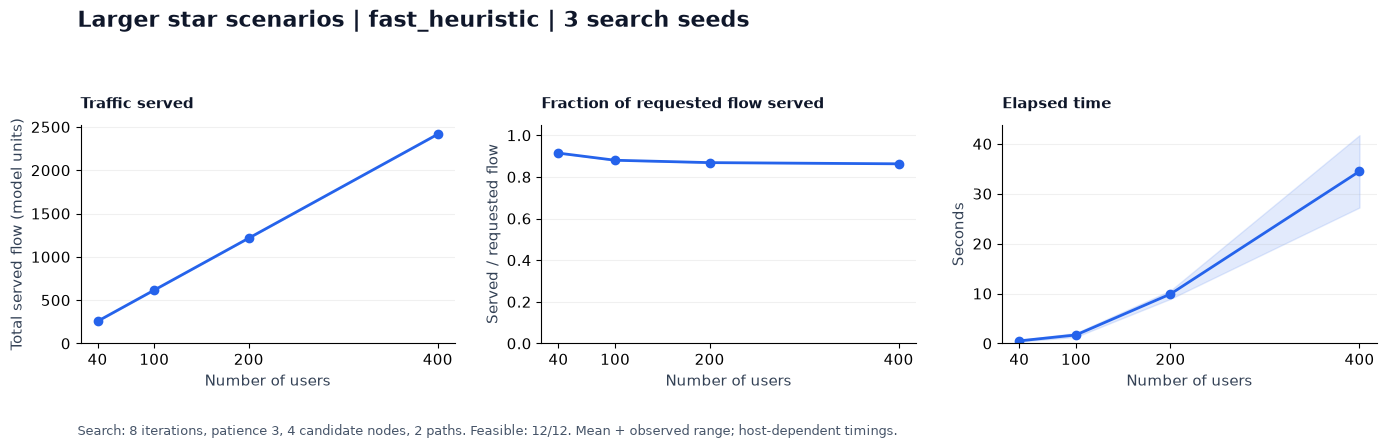

In [10]:
large_valid = large_results.loc[large_results["feasible"]]
if large_valid.empty:
    raise RuntimeError("No feasible large runs; inspect the exported errors.")
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, metric, title, ylabel in zip(
    axes,
    ["score", "served_fraction", "runtime"],
    ["Traffic served", "Fraction of requested flow served", "Elapsed time"],
    ["Total served flow (model units)", "Served / requested flow", "Seconds"],
    strict=True,
):
    stats = large_valid.groupby("users")[metric].agg(["mean", "min", "max"]).sort_index()
    x = stats.index.to_numpy()
    ax.plot(x, stats["mean"].to_numpy(), marker="o", color="#2563eb", linewidth=2)
    ax.fill_between(
        x, stats["min"].to_numpy(), stats["max"].to_numpy(), color="#2563eb", alpha=0.13
    )
    ax.set_title(title, fontsize=11, weight="bold", loc="left", pad=12)
    ax.set_xlabel("Number of users")
    ax.set_ylabel(ylabel)
    ax.set_xticks(sorted(large_results["users"].unique()))
    ax.set_ylim(bottom=0)
    if metric == "served_fraction":
        ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.18)
fig.suptitle(
    f"Larger star scenarios | {LARGE_SOLVER} | {len(LARGE_SEEDS)} search seeds",
    fontsize=16,
    weight="bold",
    x=0.06,
    ha="left",
)
fig.text(
    0.06,
    0.035,
    f"Search: {LARGE_OPTIONS['max_iter']} iterations, patience {LARGE_OPTIONS['patience']}, "
    f"{LARGE_OPTIONS['candidate_nodes']} candidate nodes, "
    f"{LARGE_OPTIONS['limit_shortest_path']} paths. "
    f"Feasible: {int(large_results['feasible'].sum())}/{len(large_results)}. "
    "Mean + observed range; host-dependent timings.",
    fontsize=9,
    color="#475569",
)
fig.tight_layout(rect=(0, 0.1, 1, 0.91), w_pad=2.0)
fig.savefig(OUTPUT_DIR / "large-benchmark-overview.png", dpi=160, facecolor="white")
plt.show()
plt.close(fig)

## 8. Inspect the largest solved network

The left panel shows **every node and every directed arc carrying traffic**.
User labels are suppressed to keep the overview readable; access points and
cloud remain labeled. The right panel isolates service S0 and shows only its
route nodes (an excerpt of the full network). The orange square marks its host;
blue/green arrows distinguish its demands, including zero-hop local service.

The last feasible seed on the largest configured size supplies the illustration;
it is not selected for the best score. If that size has no feasible run, this
section reports that fact instead of drawing an invented solution. Placements,
directed routing, flow, and per-demand latency are exported as CSV so the figures
can be inspected independently of the notebook.

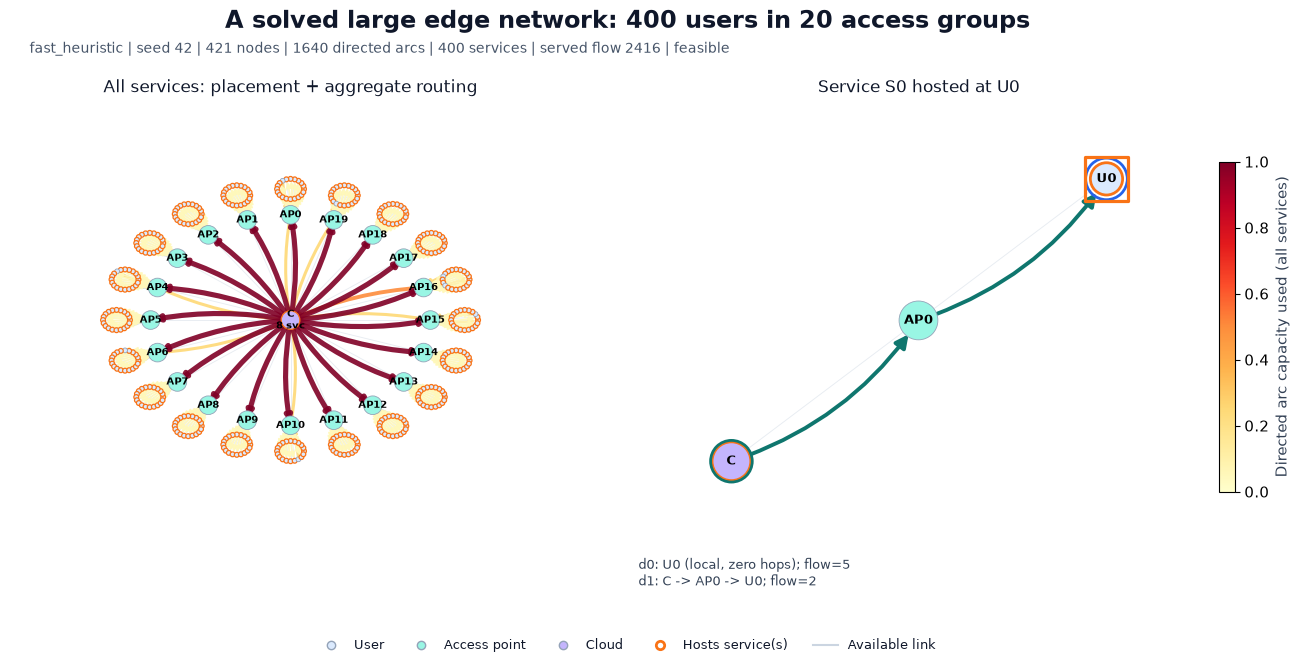

,case,nodes,directed_arcs,services,demands,objective,feasible
0,small_star,17,56,12,24,72.0,True
1,small_tree,8,24,6,12,42.0,True
2,large_star,421,1640,400,800,2416.0,True


In [6]:
if large_example is None:
    print("No feasible solution on the largest configured size; see large-benchmark-results.csv.")
else:
    problem, result, users, groups = large_example
    solution_figure(
        problem,
        result,
        star_positions(groups, LARGE_USERS_PER_GROUP),
        users,
        groups,
        "large-service-placement-routing.png",
        f"A solved large edge network: {users} users in {groups} access groups",
        detailed=False,
        focus_only=True,
    )
    network_cases.append(("large_star", problem, result, users, groups))

placements, routing, demands, network_protocol = [], [], [], []
for name, problem, result, users, groups in network_cases:
    solution, data = result.solution, problem.data
    loads = residual_arrays(data, solution.x, solution.y, solution.q)
    for service, node in zip(*np.nonzero(solution.y > 0.5), strict=True):
        placements.append(
            {
                "case": name,
                "service": int(service),
                "node": int(node),
                "node_label": node_name(int(node), users, groups),
                "service_resources": float(data.service_resources[service]),
            }
        )
    for demand, arc in zip(*np.nonzero(solution.x > 0.5), strict=True):
        u, v = data.arcs[int(arc)]
        routing.append(
            {
                "case": name,
                "demand": int(demand),
                "service": int(data.demand_to_service[demand]),
                "arc_index": int(arc),
                "source": u,
                "target": v,
                "demand_flow": float(solution.q[demand]),
                "aggregate_arc_flow": float(loads["edge_load"][arc]),
                "arc_capacity": float(data.arc_capacities[arc]),
            }
        )
    for demand in range(data.n_demands):
        service = int(data.demand_to_service[demand])
        host = int(np.flatnonzero(solution.y[service] > 0.5)[0])
        demands.append(
            {
                "case": name,
                "demand": demand,
                "service": service,
                "origin": int(data.origins[demand]),
                "host": host,
                "served_flow": float(solution.q[demand]),
                "requested_flow": float(data.max_flows[demand]),
                "latency": float(loads["demand_latency"][demand]),
                "latency_limit": float(data.latency_limits[demand]),
                "local": bool(data.origins[demand] == host),
            }
        )
    network_protocol.append(
        {
            "case": name,
            "users": users,
            "groups": groups,
            "nodes": data.n_nodes,
            "directed_arcs": data.n_arcs,
            "services": data.n_services,
            "demands": data.n_demands,
            "solver": result.solver,
            "seed": result.seed,
            "objective": result.objective,
            "runtime": result.runtime,
            "feasible": result.validation.feasible,
            "solver_options": LARGE_OPTIONS if name == "large_star" else {},
            "layout": "Schematic positions; actual topology and solution arrays.",
            "selected_service": 0,
        }
    )
pd.DataFrame(placements).to_csv(OUTPUT_DIR / "network-placements.csv", index=False)
pd.DataFrame(routing).to_csv(OUTPUT_DIR / "network-routing.csv", index=False)
pd.DataFrame(demands).to_csv(OUTPUT_DIR / "network-demands.csv", index=False)
(OUTPUT_DIR / "network-solution-protocol.json").write_text(
    json.dumps(network_protocol, indent=2) + "\n", encoding="utf-8"
)
display(
    pd.DataFrame(network_protocol)[
        ["case", "nodes", "directed_arcs", "services", "demands", "objective", "feasible"]
    ]
)

## Next: adapt the evaluation to your system

- **Change modeled constraints:** construct a new problem with
  `problem.with_data(arc_capacities=problem.data.arc_capacities * 2)` or adjust
  `node_resources` and `latency_limits`. Use the same variant for all methods.
  If you change the campaign loop, record those changes in the protocol too.
- **Train and evaluate PPO:** install the `rl` extra, add `ppo` to `SOLVERS`, and
  set `SOLVER_OPTIONS["ppo"] = {"train_step": 10000, "evaluation_step": 100}`.
  This runs training and evaluation through `solve`; it is not a held-out
  cross-topology evaluation protocol. The declared training budget may be rounded
  up by the learning backend.
- **Add a mathematical baseline:** install `exact,gurobi`, configure a license,
  and add `ilp_arc`. Its termination status and feasibility must be read together.
- **Refresh README assets:** review the feasibility summary and figures, then
  copy the reviewed figures, CSVs, and protocol JSONs from `artifacts/readme/` to
  `docs/assets/`. Update the README caption if you changed the parameters.

See [the API guide](../docs/api.md) for construction and validation contracts,
[experiments](../docs/experiments.md) for CLI and Docker execution, and
[development](../docs/development.md) for adding a solver.